# 01. Pobranie danych źródłowych

**Projekt:** Pogoda, OZE i cena prądu – analiza i prognoza zapotrzebowania na energię elektryczną w Polsce
**Etap 2 projektu:** pozyskanie danych

Notebook przedstawia pozyskanie danych ze wszystkich źródeł opisanych w rozdziale 4 koncepcji
oraz charakterystykę danych surowych. Kod pobierania znajduje się w module `src/pobieranie.py`;
notebook wywołuje jego funkcje i prezentuje uzyskane pliki.

| # | Źródło | Zawartość | Format | Okres |
|---|---|---|---|---|
| Z1 | PSE – archiwum pse.pl | zapotrzebowanie, plan dobowy, generacja wiatr i PV | CSV (1 h) | 01.01.2022 – 13.06.2024 |
| Z1 | PSE – API raporty.pse.pl | zapotrzebowanie, prognoza PSE, generacja wiatr i PV | JSON (15 min) | 14.06.2024 – 30.09.2026 |
| Z2 | ENTSO-E (kopia: energy-charts.info) | generacja według typu źródła (miks) | JSON (15 min / 1 h) | cały okres |
| Z3 | RDN – PSE (SDAC, PLN) | cena dnia następnego | JSON (15 min / 1 h) | od 14.06.2024 |
| Z3 | RDN – ENTSO-E (EUR) + kursy NBP | cena dnia następnego, kurs EUR/PLN | JSON | do 13.06.2024 |
| Z4 | Open-Meteo (reanaliza ERA5) | temperatura, wiatr 100 m, promieniowanie, zachmurzenie | JSON (1 h) | cały okres |
| Z5 | biblioteka `holidays` | dni ustawowo wolne od pracy | generowane w Pythonie | cały okres |

Zasada przyjęta w projekcie: dane surowe zapisywane są w katalogu `data/raw/` bez modyfikacji treści
(jedynie w postaci plików CSV). Pobieranie jest wznawialne – pliki pobrane wcześniej nie są
pobierane ponownie.

In [1]:
import sys
import warnings
from pathlib import Path

# ostrzeżenie biblioteki requests o wersjach zależności nie wpływa na wyniki
warnings.filterwarnings("ignore", message=".*doesn't match a supported version")

# katalog projektu (nadrzędny względem notebooks/) – dostęp do modułów src
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import wykresy
from src.wykresy import format_polski

wykresy.ustaw_styl()

## 1. Parametry pobierania

Okres analizy, data zmiany źródła danych PSE oraz lokalizacje pomiarów pogodowych zdefiniowane są
w module `src/konfiguracja.py`. Wagi lokalizacji wykorzystywane są na etapie integracji
(notebook 02) do wyznaczenia ogólnopolskich wartości pogodowych.

In [2]:
from src import pobieranie
from src.konfiguracja import DANE_SUROWE, DATA_DO, DATA_OD, LOKALIZACJE, REFORMA_RB

print(f"Okres analizy: {DATA_OD} – {DATA_DO}")
print(f"Zmiana źródła danych PSE (reforma rynku bilansującego): {REFORMA_RB}")
pd.DataFrame(LOKALIZACJE).set_index("id")

Okres analizy: 2022-01-01 – 2026-09-30
Zmiana źródła danych PSE (reforma rynku bilansującego): 2024-06-14


,nazwa,wojewodztwo,lat,lon,waga_ludnosc,waga_wiatr
id,,,,,,
WAW,Warszawa,mazowieckie,"52,23","21,01","5,51","0,06"
KRK,Kraków,małopolskie,"50,06","19,94","3,43","0,01"
WRO,Wrocław,dolnośląskie,"51,11","17,04","2,88","0,05"
POZ,Poznań,wielkopolskie,"52,41","16,93","3,49","0,17"
GDN,Gdańsk,pomorskie,"54,35","18,65","2,36","0,14"
SZZ,Szczecin,zachodniopomorskie,"53,43","14,55","1,65","0,25"
LDZ,Łódź,łódzkie,"51,76","19,46","2,38","0,10"
KTW,Katowice,śląskie,"50,26","19,02","4,35","0,01"
BIA,Białystok,podlaskie,"53,13","23,16","1,15","0,12"


## 2. Pobranie danych

Funkcja `pobierz_wszystko()` pobiera kolejno wszystkie źródła. Zapytania wysyłane są w porcjach
wynikających z ograniczeń serwerów:

* archiwum PSE – maksymalnie 31 dni na zapytanie; odpowiedź w postaci strony HTML oznacza
  przekroczenie limitu, wówczas program odczekuje i ponawia zapytanie,
* API PSE – dane pobierane miesiącami, z obsługą stronicowania (`nextLink`),
* energy-charts.info – miesiącami, z ponawianiem przy kodzie 429 (limit zapytań),
* NBP – maksymalnie 93 dni na zapytanie,
* Open-Meteo – cały okres jednym zapytaniem dla każdej lokalizacji.

Pełne pobranie trwa ok. 1–2 godzin (głównie ze względu na limity serwera PSE). Ponieważ dane
zostały już pobrane, poniższe wywołanie jedynie sprawdza kompletność plików.

In [3]:
pobieranie.pobierz_wszystko()

Z4 – pogoda (Open-Meteo)
Z2 – miks energetyczny
  źródło miksu: energy-charts.info (dane ENTSO-E)
Z3 – ceny
Z1 – PSE, API (od 14.06.2024)
Z1 – PSE, archiwum CSV (do 13.06.2024)


## 3. Zestawienie pobranych plików

In [4]:
wiersze = []
for katalog in sorted(p for p in DANE_SUROWE.rglob("*") if p.is_dir()):
    pliki = sorted(katalog.glob("*.csv"))
    if pliki:
        wiersze.append({
            "katalog": katalog.relative_to(DANE_SUROWE).as_posix(),
            "liczba_plikow": len(pliki),
            "rozmiar_mb": sum(p.stat().st_size for p in pliki) / 1e6,
            "liczba_wierszy": sum(sum(1 for _ in open(p, encoding="utf-8")) - 1 for p in pliki),
        })
spis = pd.DataFrame(wiersze).set_index("katalog")
spis.loc["razem"] = spis.sum()
spis.astype({"liczba_plikow": int, "liczba_wierszy": int})

,liczba_plikow,rozmiar_mb,liczba_wierszy
katalog,,,
ceny,2,"0,74",22701
miks/energy_charts,57,"40,97",1109729
pogoda,10,"14,84",416400
pse_api/csdac-pln,28,"10,66",80544
pse_api/his-wlk-cal,28,"17,88",80544
pse_api/kse-load,28,"11,75",80544
pse_archiwum/PL_GEN_WIATR,29,"0,66",21479
pse_archiwum/PL_PD_GO_BILANS,29,"1,84",21479
pse_archiwum/PL_WYK_KSE,29,"1,31",21479


Łącznie pobrano ok. 100 MB danych surowych. Największą część stanowią dane 15-minutowe
(API PSE od 14.06.2024 r. oraz miks energetyczny w formacie długim: jeden wiersz = okres × typ źródła).

Poniższy wykres przedstawia zakres czasowy poszczególnych źródeł. Dane PSE i ceny energii pochodzą
z dwóch różnych źródeł przed i po 14.06.2024 r. – zostaną połączone w jeden szereg w notebooku 02.

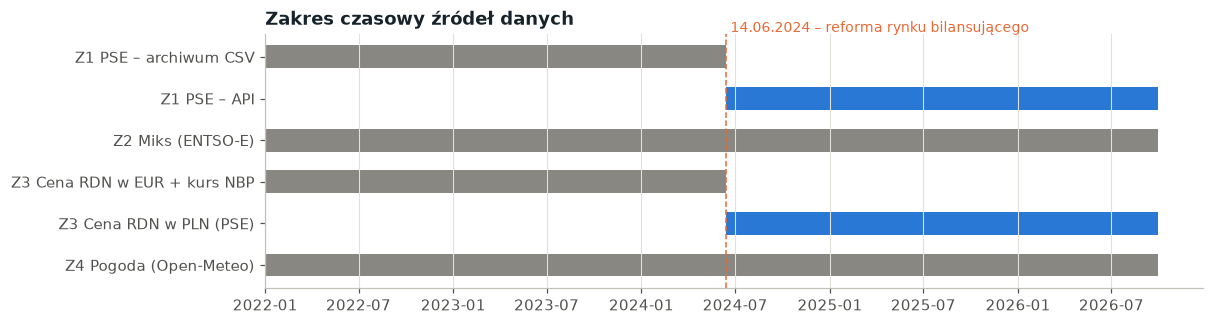

In [5]:
zakresy = [
    ("Z1 PSE – archiwum CSV", DATA_OD, "2024-06-13"),
    ("Z1 PSE – API", REFORMA_RB, DATA_DO),
    ("Z2 Miks (ENTSO-E)", DATA_OD, DATA_DO),
    ("Z3 Cena RDN w EUR + kurs NBP", DATA_OD, "2024-06-13"),
    ("Z3 Cena RDN w PLN (PSE)", REFORMA_RB, DATA_DO),
    ("Z4 Pogoda (Open-Meteo)", DATA_OD, DATA_DO),
]
fig, ax = plt.subplots(figsize=(11, 3))
for i, (nazwa, od, do) in enumerate(reversed(zakresy)):
    od, do = pd.Timestamp(od), pd.Timestamp(do)
    ax.barh(i, (do - od).days, left=od, height=0.55, color=wykresy.NIEBIESKI if "API" in nazwa or "PLN" in nazwa
            else wykresy.TUSZ_WYCISZONY)
ax.set_yticks(range(len(zakresy)), [z[0] for z in reversed(zakresy)])
ax.axvline(pd.Timestamp(REFORMA_RB), color=wykresy.POMARANCZOWY, linestyle="--", linewidth=1)
ax.text(pd.Timestamp(REFORMA_RB), len(zakresy) - 0.4, " 14.06.2024 – reforma rynku bilansującego",
        color=wykresy.POMARANCZOWY, fontsize=9)
ax.set_title("Zakres czasowy źródeł danych")
ax.grid(axis="y", visible=False)
plt.show()

## 4. Charakterystyka danych surowych

### Z1. PSE – archiwum raportów (CSV)

Pliki archiwalne PSE zapisane są w kodowaniu Windows-1250, z separatorem `;` i przecinkiem
dziesiętnym. Czas podawany jest jako data i numer godziny doby handlowej (1–24, w dniach zmiany
czasu 23 lub 25 godzin).

In [6]:
katalog = DANE_SUROWE / "pse_archiwum" / "PL_WYK_KSE"
przyklad = pd.read_csv(sorted(katalog.glob("*.csv"))[0], sep=";", dtype=str)
przyklad.head()

,Data,Godzina,Krajowe zapotrzebowanie na moc,Sumaryczna generacja JWCD,Sumaryczna generacja nJWCD,Krajowe saldo wymiany międzysystemowej równoległej,Krajowe saldo wymiany międzysystemowej nierównoległej
0,2022-01-01,1,"14910,838","6470,388","8656,263","-955,963","783,663"
1,2022-01-01,2,"14438,250","6381,288","8628,425","-959,363","796,300"
2,2022-01-01,3,"13934,850","6462,650","8447,588","-1159,250","874,763"
3,2022-01-01,4,"13579,013","6606,600","8366,888","-1263,850","737,575"
4,2022-01-01,5,"13396,763","6357,138","8502,813","-1315,625","718,975"


In [7]:
# liczba godzin w dobach zmiany czasu (wiosna: 23, jesień: 25)
archiwum = pd.concat([pd.read_csv(p, sep=";", dtype=str) for p in sorted(katalog.glob("*.csv"))])
godziny_w_dobie = archiwum.groupby("Data").size()
godziny_w_dobie[godziny_w_dobie != 24]

Data
2022-03-27    23
2022-10-30    25
2023-03-26    23
2023-10-29    25
2024-03-31    23
dtype: int64

### Z1. PSE – API raporty.pse.pl (JSON)

Od 14.06.2024 r. PSE publikuje dane w rozdzielczości 15-minutowej. Odpowiedź API ma postać
dokumentu JSON z listą rekordów w polu `value`. Przykład zapytania o zapotrzebowanie na moc
w ostatniej dobie okresu analizy (filtr w składni OData):

In [8]:
import requests

odpowiedz = requests.get(
    "https://api.raporty.pse.pl/api/kse-load",
    params={"$filter": f"business_date eq '{DATA_DO}'", "$first": 2},
    timeout=60,
)
odpowiedz.json()["value"]

[{'dtime': '2026-09-30 00:15:00',
  'period': '00:00 - 00:15',
  'dtime_utc': '2026-09-29 22:15:00',
  'load_fcst': 15750.0,
  'period_utc': '22:00 - 22:15',
  'load_actual': 15654.459,
  'business_date': '2026-09-30',
  'publication_ts': '2026-10-01 03:05:10.180',
  'publication_ts_utc': '2026-10-01 01:05:10.180'},
 {'dtime': '2026-09-30 00:30:00',
  'period': '00:15 - 00:30',
  'dtime_utc': '2026-09-29 22:30:00',
  'load_fcst': 15500.0,
  'period_utc': '22:15 - 22:30',
  'load_actual': 15610.287,
  'business_date': '2026-09-30',
  'publication_ts': '2026-10-01 03:05:10.180',
  'publication_ts_utc': '2026-10-01 01:05:10.180'}]

Pole `dtime_utc` oznacza **koniec** okresu 15-minutowego (np. 23:15 UTC dla okresu 23:00–23:15),
co uwzględniono przy agregacji do godzin. Zapisane pliki zawierają rekordy w niezmienionej postaci:

In [9]:
api = pd.concat(pd.read_csv(p) for p in sorted((DANE_SUROWE / "pse_api" / "kse-load").glob("*.csv")))
print(f"Liczba rekordów 15-minutowych: {len(api):,}".replace(",", " "))
api[["dtime_utc", "period", "business_date", "load_actual", "load_fcst"]].head(8)

Liczba rekordów 15-minutowych: 80 544


,dtime_utc,period,business_date,load_actual,load_fcst
0,2024-06-13 22:15:00,00:00 - 00:15,2024-06-14,"16 295,30","15 700,00"
1,2024-06-13 22:30:00,00:15 - 00:30,2024-06-14,"15 964,03","15 400,00"
2,2024-06-13 22:45:00,00:30 - 00:45,2024-06-14,"15 772,47","15 100,00"
3,2024-06-13 23:00:00,00:45 - 01:00,2024-06-14,"15 695,53","14 850,00"
4,2024-06-13 23:15:00,01:00 - 01:15,2024-06-14,"15 606,19","14 650,00"
5,2024-06-13 23:30:00,01:15 - 01:30,2024-06-14,"15 484,91","14 500,00"
6,2024-06-13 23:45:00,01:30 - 01:45,2024-06-14,"15 248,14","14 400,00"
7,2024-06-14 00:00:00,01:45 - 02:00,2024-06-14,"15 028,91","14 250,00"


In [10]:
# liczba okresów 15-minutowych w dobie: 96, w dobach zmiany czasu 92 lub 100
api.groupby("business_date").size().value_counts().rename("liczba dób")

96     835
100      2
92       2
Name: liczba dób, dtype: int64

### Z2. Miks energetyczny (ENTSO-E)

Generacja według typu źródła zapisana jest w formacie długim. Typy źródeł oznaczone są kodami
PsrType platformy ENTSO-E (np. B05 – węgiel kamienny, B19 – wiatr na lądzie, B16 – fotowoltaika).
Rozdzielczość danych zmienia się w czasie z 1 h na 15 min.

In [11]:
miks = pd.concat(pd.read_csv(p) for p in sorted((DANE_SUROWE / "miks" / "energy_charts").glob("*.csv")))
miks["czas_utc"] = pd.to_datetime(miks["czas_utc"], utc=True)
print(f"Liczba rekordów: {len(miks):,}".replace(",", " "))
miks.head()

Liczba rekordów: 1 109 729


,czas_utc,kod_zrodla,generacja_mw
0,2021-12-31 23:00:00+00:00,B11,"175,10"
1,2022-01-01 00:00:00+00:00,B11,"176,30"
2,2022-01-01 01:00:00+00:00,B11,"199,30"
3,2022-01-01 02:00:00+00:00,B11,"216,00"
4,2022-01-01 03:00:00+00:00,B11,"238,10"


In [12]:
# średnia generacja [MW] i odsetek braków dla każdego typu źródła
miks.groupby("kod_zrodla")["generacja_mw"].agg(
    srednia_mw="mean", braki_proc=lambda s: 100 * s.isna().mean()).sort_values("srednia_mw", ascending=False)

,srednia_mw,braki_proc
kod_zrodla,,
B05,"6 532,81","0,00"
B02,"3 658,37","0,00"
B19,"2 420,68","0,00"
B16,"2 254,73","0,00"
B04,"2 073,65","0,00"
B20,"593,72","1,57"
B01,"289,28","0,00"
B06,"194,65","0,00"
B10,"141,04","0,00"


In [13]:
# rozdzielczość danych w kolejnych latach (najczęstszy odstęp między pomiarami)
odstepy = miks[miks["kod_zrodla"] == "B05"].sort_values("czas_utc")
odstepy = odstepy.assign(rok=odstepy["czas_utc"].dt.year, odstep=odstepy["czas_utc"].diff()).dropna()
odstepy.groupby("rok")["odstep"].agg(lambda s: s.value_counts().idxmax())

rok
2022   0 days 01:00:00
2023   0 days 01:00:00
2024   0 days 01:00:00
2025   0 days 00:15:00
2026   0 days 00:15:00
Name: odstep, dtype: timedelta64[us]

Dane miksu są kompletne. Wyjątek stanowi wiatr na morzu (B18): do maja 2026 r. przyjmuje wartość 0,
w czerwcu 2026 r. nie jest raportowany, a od lipca 2026 r. widoczna jest generacja z pierwszej
polskiej morskiej farmy wiatrowej (maksymalnie ok. 276 MW). Brak pomiaru w formacie długim
oznacza brak wiersza w tabeli faktów miksu – nie wpływa to na sumy generacji.

### Z3. Ceny Rynku Dnia Następnego i kursy NBP

In [14]:
ceny_eur = pd.read_csv(DANE_SUROWE / "ceny" / "ceny_dnia_nastepnego_eur.csv")
kursy = pd.read_csv(DANE_SUROWE / "ceny" / "kurs_eur_nbp.csv")
sdac = pd.concat(pd.read_csv(p) for p in sorted((DANE_SUROWE / "pse_api" / "csdac-pln").glob("*.csv")))
print(f"Ceny w EUR: {len(ceny_eur)} rekordów, kursy NBP: {len(kursy)} notowań, "
      f"ceny SDAC w PLN: {len(sdac)} rekordów")
display(ceny_eur.head(3), kursy.head(3), sdac[["dtime_utc", "period", "csdac_pln"]].head(3))

Ceny w EUR: 21505 rekordów, kursy NBP: 1196 notowań, ceny SDAC w PLN: 80544 rekordów


,czas_utc,cena_eur_mwh
0,2021-12-31 23:00:00+00:00,"59,03"
1,2022-01-01 00:00:00+00:00,"49,37"
2,2022-01-01 01:00:00+00:00,"43,22"


,data,kurs_eur_pln
0,2022-01-03,"4,59"
1,2022-01-04,"4,57"
2,2022-01-05,"4,57"


,dtime_utc,period,csdac_pln
0,2024-06-13 22:15:00,00:00 - 00:15,"941,06"
1,2024-06-13 22:30:00,00:15 - 00:30,"941,06"
2,2024-06-13 22:45:00,00:30 - 00:45,"941,06"


Kursy NBP publikowane są wyłącznie w dni robocze – w weekendy i święta przy przeliczeniu stosowany
jest ostatni opublikowany kurs (notebook 02).

### Z4. Pogoda (Open-Meteo, reanaliza ERA5)

Dla każdej z 10 lokalizacji pobrano jeden plik z danymi godzinowymi w czasie UTC.

In [15]:
pogoda = pd.read_csv(DANE_SUROWE / "pogoda" / "WAW.csv")
print(f"Warszawa: {len(pogoda)} godzin, braki: {pogoda.isna().sum().sum()}")
pogoda.describe().T

Warszawa: 41640 godzin, braki: 0


,count,mean,std,min,25%,50%,75%,max
temperature_2m,"41 640,00","10,58","8,96","-21,60","3,50","10,40","17,50","38,20"
wind_speed_100m,"41 640,00","5,76","2,60","0,00","3,93","5,64","7,30","20,73"
shortwave_radiation,"41 640,00","141,86","215,60","0,00","0,00","8,00","220,25","888,00"
cloud_cover,"41 640,00","65,30","40,98","0,00","20,00","94,00","100,00","100,00"


### Z5. Kalendarz dni wolnych

Dni ustawowo wolne od pracy generowane są przez bibliotekę `holidays` (uwzględnia m.in. Wigilię,
która jest dniem wolnym od 2025 r.).

In [16]:
import holidays

swieta = holidays.Poland(years=[2025, 2026], language="pl")
pd.Series(swieta).sort_index().rename("święto").to_frame()

,święto
2025-01-01,Nowy Rok
2025-01-06,Święto Trzech Króli
2025-04-20,Niedziela Wielkanocna
2025-04-21,Poniedziałek Wielkanocny
2025-05-01,Święto Państwowe
2025-05-03,Święto Narodowe Trzeciego Maja
2025-06-08,Zielone Świątki
2025-06-19,Dzień Bożego Ciała
2025-08-15,Wniebowzięcie Najświętszej Marii Panny
2025-11-01,Uroczystość Wszystkich Świętych


## Podsumowanie

* Pobrano dane z czterech niezależnych instytucji (PSE, ENTSO-E, RDN/NBP, Open-Meteo) oraz
  wygenerowano kalendarz świąt – łącznie ok. 100 MB danych surowych.
* Dane różnią się formatem (CSV w kodowaniu Windows-1250, JSON), rozdzielczością czasową
  (15 min, 1 h, 1 doba), strefą czasową (czas lokalny z dobą handlową, UTC) oraz jednostkami
  (EUR i PLN) – ujednolicenie opisano w notebooku 02.
* Dla danych PSE i cen energii konieczne jest połączenie dwóch źródeł na granicy 14.06.2024 r.